In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
ads = pd.read_csv("../data/Ad_table.csv")

C:\Users\jchmo\AppData\Local\Temp\ipykernel_64208\4006633679.py:1: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  ads = pd.read_csv("../data/Ad_table.csv")


In [30]:
print("dataset shape:", ads.shape)
print("columns: ", ads.columns.tolist())

dataset shape: (268255, 16)
columns:  ['Maker', 'Genmodel', 'Genmodel_ID', 'Adv_ID', 'Adv_year', 'Adv_month', 'Color', 'Reg_year', 'Bodytype', 'Runned_Miles', 'Engin_size', 'Gearbox', 'Fuel_type', 'Price', 'Seat_num', 'Door_num']


In [31]:
print(ads.duplicated().sum())

0


In [32]:
print(ads.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 268255 entries, 0 to 268254
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Maker         268255 non-null  object 
 1   Genmodel      268255 non-null  object 
 2   Genmodel_ID   268255 non-null  object 
 3   Adv_ID        268255 non-null  object 
 4   Adv_year      268255 non-null  int64  
 5   Adv_month     268255 non-null  int64  
 6   Color         246380 non-null  object 
 7   Reg_year      268248 non-null  float64
 8   Bodytype      267301 non-null  object 
 9   Runned_Miles  267200 non-null  object 
 10  Engin_size    266191 non-null  object 
 11  Gearbox       268088 non-null  object 
 12  Fuel_type     267846 non-null  object 
 13  Price         268255 non-null  object 
 14  Seat_num      261781 non-null  float64
 15  Door_num      263702 non-null  float64
dtypes: float64(3), int64(2), object(11)
memory usage: 32.7+ MB
None


In [33]:
print(ads["Price"].head(10))

0    21500
1    28750
2    29999
3    34948
4    26555
5    24950
6    29995
7    22450
8    26990
9    29995
Name: Price, dtype: object


In [34]:
for col in ["Price", "Runned_Miles", "Reg_year", "Adv_year"]:
    ads[col] = pd.to_numeric(ads[col], errors="coerce")

In [35]:
ads_clean = ads[
    ads["Price"].notna() & (ads["Price"] > 0)
].copy()

In [36]:
print("Počet všetkých inzerátov:", len(ads))
print("Inzeráty s platnou cenou:", len(ads_clean))
print("Počet rôznych modelov:", ads_clean["Genmodel"].nunique())

Počet všetkých inzerátov: 268255
Inzeráty s platnou cenou: 267110
Počet rôznych modelov: 890


In [37]:
display(
    ads_clean[["Price", "Runned_Miles", "Reg_year"]]
    .describe()
    .round(2)
)

,Price,Runned_Miles,Reg_year
count,267110.00,265807.00,267110.00
mean,14756.26,48197.76,2012.71
std,32320.91,41855.02,4.47
min,100.00,0.00,1900.00
25%,4990.00,14198.50,2010.00
50%,9299.00,39326.00,2014.00
75%,17150.00,75000.00,2016.00
max,9999999.00,6363342.00,2019.00


In [38]:
bmw_ads = ads_clean[
    ads_clean["Maker"].astype(str).str.strip().str.upper() == "BMW"
].copy()

print("Počet BMW inzerátov:", len(bmw_ads))
print("Počet modelov BMW:", bmw_ads["Genmodel"].nunique())

display(bmw_ads.head())


Počet BMW inzerátov: 16049
Počet modelov BMW: 36


,Maker,Genmodel,Genmodel_ID,Adv_ID,Adv_year,Adv_month,Color,Reg_year,Bodytype,Runned_Miles,Engin_size,Gearbox,Fuel_type,Price,Seat_num,Door_num
194965,BMW,5 Series Gran Turismo,8_10,8_10$$1,2018,6,Silver,2010.0,Hatchback,71000.0,3.0L,Automatic,Diesel,11975.0,5.0,5.0
194966,BMW,5 Series Gran Turismo,8_10,8_10$$2,2018,5,Black,2012.0,Hatchback,49989.0,3.0L,Automatic,Diesel,15890.0,5.0,5.0
194967,BMW,5 Series Gran Turismo,8_10,8_10$$3,2018,6,White,2012.0,Hatchback,65000.0,2.0L,Automatic,Diesel,15839.0,5.0,5.0
194968,BMW,5 Series Gran Turismo,8_10,8_10$$4,2018,6,Silver,2010.0,Hatchback,91634.0,3.0L,Automatic,Diesel,9795.0,5.0,5.0
194969,BMW,5 Series Gran Turismo,8_10,8_10$$5,2018,3,Silver,2015.0,Hatchback,93000.0,2.0L,Automatic,Diesel,15000.0,5.0,5.0


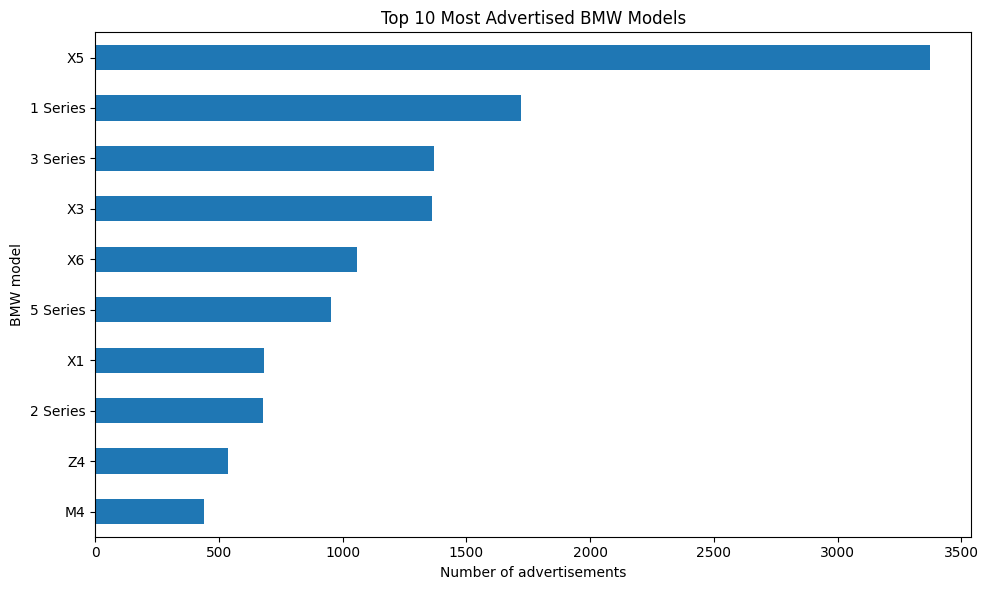

In [ ]:
model_counts = (
    bmw_ads["Genmodel"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
model_counts.plot(kind="barh")

plt.title("Top 10 Most Advertised BMW Models")
plt.xlabel("Number of advertisements")
plt.ylabel("BMW model")
plt.tight_layout()
#plt.savefig("bmw_top_models.png", dpi=200, bbox_inches="tight")
plt.show()


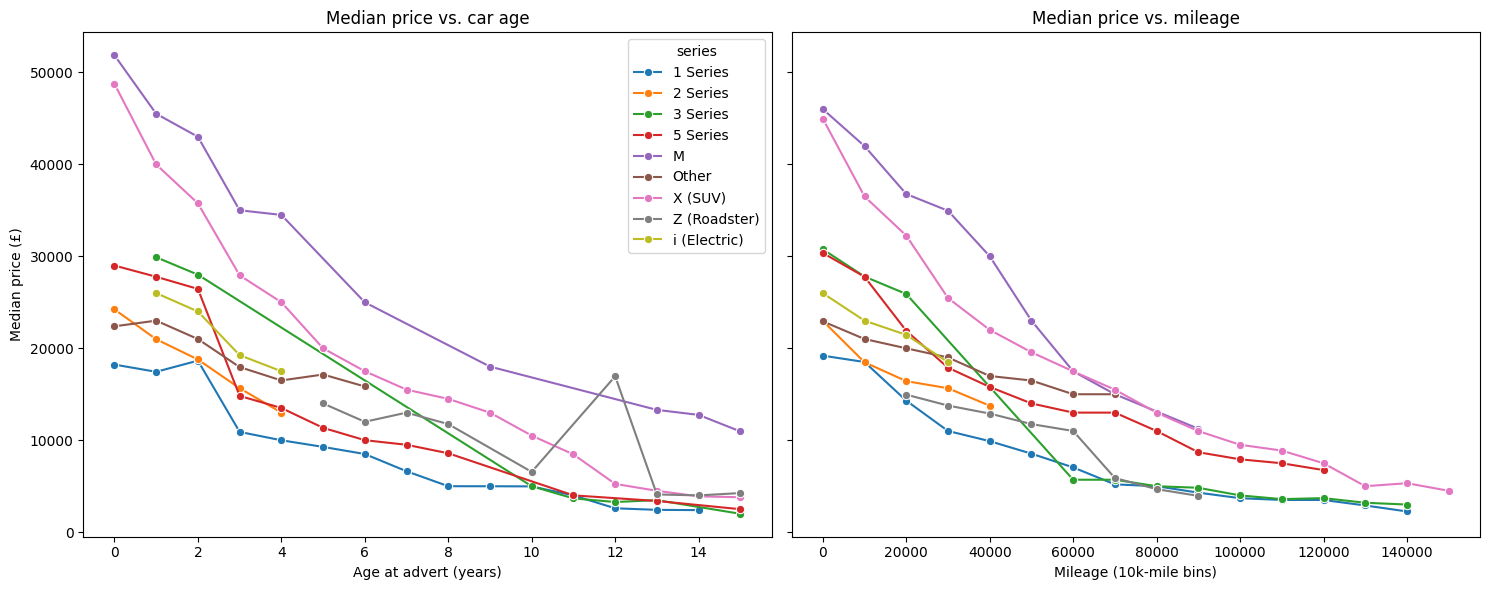

In [40]:
# Depreciation

# clean data
df = bmw_ads.copy()

df["car_age"] = df["Adv_year"] - df["Reg_year"]
df["Runned_Miles"] = pd.to_numeric(df["Runned_Miles"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df = df[
    df["car_age"].between(0, 15)
    & (df["Price"] > 500)
    & df["Runned_Miles"].between(0, 200_000)
].dropna(subset=["car_age", "Price", "Runned_Miles"])

# group Genmodel into series

def to_series(model):
    m = str(model).strip().upper()
    if m.endswith("SERIES"):
        return m.title()          # "3 Series"
    if m.startswith("X"):
        return "X (SUV)"
    if m.startswith("Z"):
        return "Z (Roadster)"
    if m.startswith("I"):
        return "i (Electric)"
    if m.startswith("M"):
        return "M"
    return "Other"
    
df["series"] = df["Genmodel"].apply(to_series)

# keep only series with enough ads
counts = df["series"].value_counts()
keep = counts[counts >= 500].index
df = df[df["series"].isin(keep)]
order = sorted(keep)

# median price vs age
by_age = (df.groupby(["series", "car_age"])["Price"]
            .agg(median="median", n="size").reset_index())
by_age = by_age[by_age["n"] >= 30]  

# median price vs mileage (10k-mile bins)
df["miles_bin"] = (df["Runned_Miles"] // 10_000) * 10_000
by_miles = (df.groupby(["series", "miles_bin"])["Price"]
              .agg(median="median", n="size").reset_index())
by_miles = by_miles[by_miles["n"] >= 30]

# plot 
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.lineplot(data=by_age, x="car_age", y="median", hue="series",
             hue_order=order, marker="o", ax=axes[0])
axes[0].set(title="Median price vs. car age",
            xlabel="Age at advert (years)", ylabel="Median price (£)")

sns.lineplot(data=by_miles, x="miles_bin", y="median", hue="series",
             hue_order=order, marker="o", ax=axes[1], legend=False)
axes[1].set(title="Median price vs. mileage",
            xlabel="Mileage (10k-mile bins)", ylabel="")

plt.tight_layout()
plt.savefig("../images/bmw_price_vs_age_mileage.png", dpi=150)
plt.show()

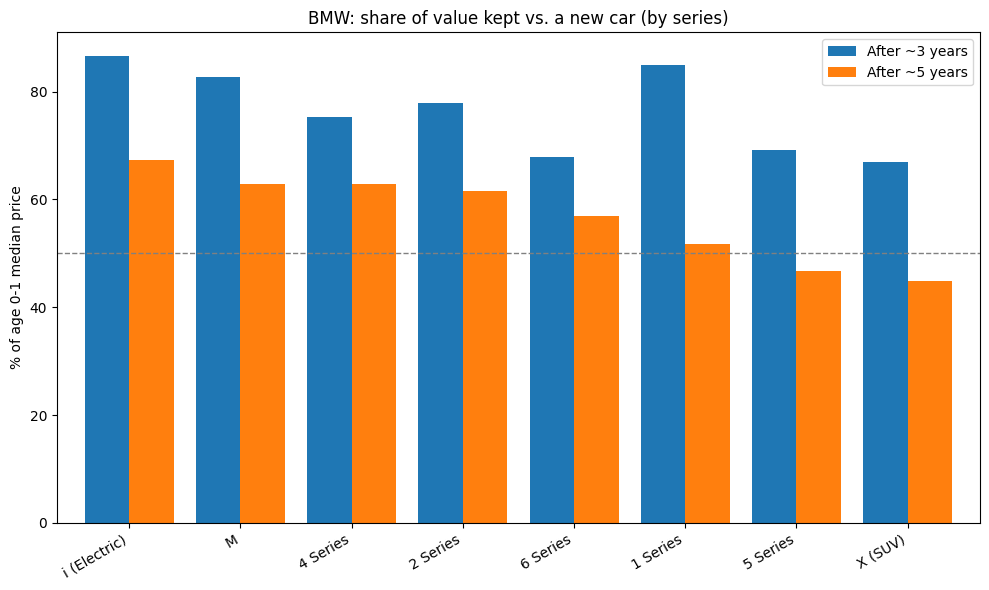

              After ~3 years  After ~5 years
series                                      
i (Electric)            87.0            67.0
M                       83.0            63.0
4 Series                75.0            63.0
2 Series                78.0            62.0
6 Series                68.0            57.0
1 Series                85.0            52.0
5 Series                69.0            47.0
X (SUV)                 67.0            45.0


In [41]:
import re
df = df[df["car_age"].between(0, 15) & (df["Price"] > 500)]
df = df[~df["Genmodel"].isin(["Z3M", "Z4M", "Z8"])]   # rare collectibles

def to_series(model):
    m = str(model).strip()
    if (g := re.match(r"^(\d) Series", m, flags=re.I)): return f"{g.group(1)} Series"
    if re.match(r"^X\d", m, flags=re.I): return "X (SUV)"
    if re.match(r"^Z\d", m, flags=re.I): return "Z (Roadster)"
    if re.match(r"^i\d", m, flags=re.I): return "i (Electric)"
    if re.match(r"^M\d", m, flags=re.I): return "M"
    return "Other"

df["series"] = df["Genmodel"].apply(to_series)

# --- retention: median price at target age / median price at age 0-1 ---
def retention(ages, min_n=30):
    base = df[df["car_age"] <= 1].groupby("series")["Price"].agg(["median", "size"])
    tgt  = df[df["car_age"].isin(ages)].groupby("series")["Price"].agg(["median", "size"])
    r = (tgt["median"] / base["median"]) * 100
    r[(base["size"] < min_n) | (tgt["size"] < min_n)] = np.nan
    return r

res = pd.DataFrame({
    "After ~3 years": retention([2, 3, 4]),
    "After ~5 years": retention([4, 5, 6]),
}).drop(index="Other", errors="ignore").sort_values("After ~5 years", ascending=False)

res = res.drop(index=["Other", "3 Series", "Z (Roadster)"], errors="ignore")

# --- plot ---
ax = res.plot(kind="bar", figsize=(10, 6), width=0.8)
ax.set(title="BMW: share of value kept vs. a new car (by series)",
       ylabel="% of age 0-1 median price", xlabel="")
ax.axhline(50, color="grey", ls="--", lw=1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../images/bmw_retention_by_series.png", dpi=150)
plt.show()
print(res.round(0))

In [42]:
fuel = bmw_ads.copy()

In [43]:
fuel["car_age"] = fuel["Adv_year"] - fuel["Reg_year"]
fuel["Runned_Miles"] = pd.to_numeric(fuel["Runned_Miles"], errors="coerce")
fuel["Price"] = pd.to_numeric(fuel["Price"], errors="coerce")

In [44]:
print(fuel["Fuel_type"].value_counts())

Fuel_type
Diesel                             10510
Petrol                              4776
Hybrid  Petrol/Electric Plug-in      361
Electric                             248
Petrol Plug-in Hybrid                103
Diesel Hybrid                         25
Hybrid  Petrol/Electric                8
Petrol Hybrid                          6
Name: count, dtype: int64


In [45]:
def fuel_group(f):
    f = str(f).lower()
    if "hybrid" in f: return "Hybrid"
    if "electric" in f: return "Electric"
    if "diesel" in f: return "Diesel"
    if "petrol" in f: return "Petrol"
    return None

In [46]:
fuel["fuel_group"] = fuel["Fuel_type"].apply(fuel_group)
fuel = fuel.dropna(subset=["fuel_group"])

            After ~3 years  After ~5 years
fuel_group                                
Hybrid               104.0            53.0
Petrol                88.0            54.0
Electric              73.0             NaN
Diesel                66.0            46.0
fuel_group
Diesel      2331
Petrol       336
Hybrid        41
Electric      26
Name: count, dtype: int64


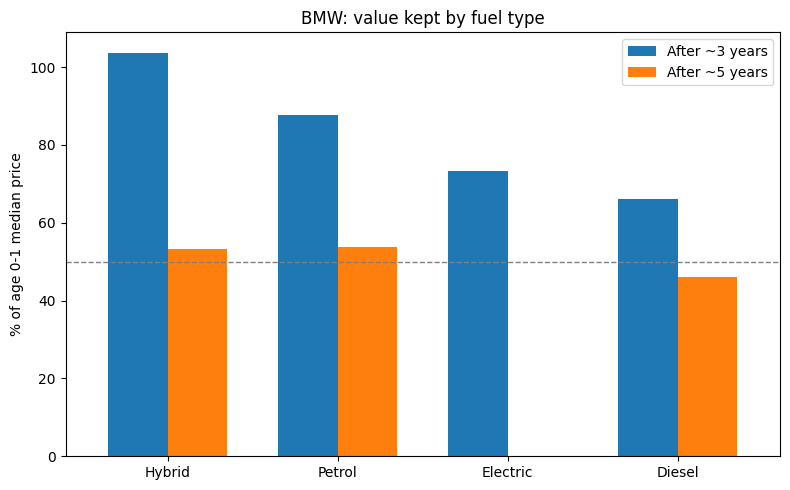

In [47]:
def retention(data, group_cols, ages, min_n=30):
    base = data[data["car_age"] <= 1].groupby(group_cols)["Price"].agg(["median", "size"])
    tgt = data[data["car_age"].isin(ages)].groupby(group_cols)["Price"].agg(["median", "size"])
    r = (tgt["median"] / base["median"]) * 100
    r[(base["size"] < min_n) | (tgt["size"] < min_n)] = np.nan
    return r

res = pd.DataFrame({
    "After ~3 years": retention(fuel, ["fuel_group"], [2, 3, 4]),
    "After ~5 years": retention(fuel, ["fuel_group"], [4, 5, 6]),
}).sort_values("After ~3 years", ascending=False)

print(res.round(0))
print(fuel[fuel["car_age"].isin([4, 5, 6])]["fuel_group"].value_counts())  # sample sizes

# --- 5. Plot ---
ax = res.plot(kind="bar", figsize=(8, 5), width=0.7)
ax.set(title="BMW: value kept by fuel type",
       ylabel="% of age 0-1 median price", xlabel="")
ax.axhline(50, color="grey", ls="--", lw=1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/bmw_retention_by_fuel.png", dpi=150)
plt.show()